In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.linear_model as lm
import sklearn.pipeline as pipe
import sklearn.preprocessing as pp
import sklearn.model_selection as ms
import sklearn.ensemble as rf
import numpy as np

In [2]:
data = np.load("data/mnist/mnist.npz")
data

NpzFile 'data/mnist/mnist.npz' with keys: x_test, x_train, y_train, y_test

In [3]:
xtrain = data["x_train"]
ytrain = data["y_train"]
xtest = data["x_test"]
ytest = data["y_test"]
xtrain.shape, ytrain.shape

((60000, 28, 28), (60000,))

In [4]:
xtrain = xtrain.reshape(-1, 28*28)
xtest = xtest.reshape(-1, 28*28)
xtrain.shape

(60000, 784)

In [5]:
# Faire le modèle knn avec k=3
# Afficher le score de test et le score de train
# ypred contient la prédiction du jeu de test
# MEttre à jour matplotlib pour afficher les valeurs prédites
#Tester plusieurs valeurs de k

In [6]:
model = rf.RandomForestClassifier()
model.fit(xtrain, ytrain)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [7]:
ypred = model.predict(xtest)

In [8]:
test_score = model.score(xtest, ytest)
test_score

0.9691

In [9]:
select = np.random.randint(xtest.shape[0], size=12)
xtest = xtest.reshape(-1, 28, 28)


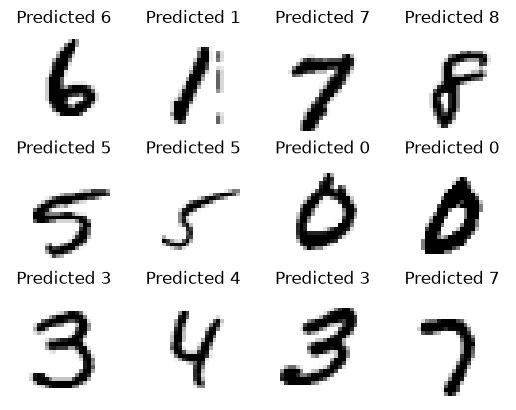

In [10]:
for index, value in enumerate(select):
    plt.subplot(3,4, index + 1)
    plt.axis("off")
    plt.imshow(xtest[value], cmap=plt.cm.gray_r)
    plt.title(f"Predicted {ypred[value]}")
plt.show()

In [11]:
errors = ytest != ypred
xerrors = xtest[errors]
yerrors = ypred[errors]
yerrors

array([8, 6, 0, 4, 3, 1, 7, 3, 9, 7, 9, 0, 8, 5, 7, 3, 2, 5, 4, 4, 7, 2,
       9, 8, 3, 9, 6, 8, 9, 2, 2, 4, 3, 7, 5, 4, 2, 0, 5, 9, 4, 8, 6, 8,
       8, 1, 8, 3, 4, 3, 2, 4, 9, 0, 3, 1, 9, 2, 9, 7, 2, 6, 2, 8, 3, 5,
       0, 1, 9, 5, 7, 6, 3, 3, 9, 7, 3, 0, 3, 2, 7, 5, 9, 4, 8, 2, 2, 9,
       3, 8, 7, 9, 4, 1, 0, 7, 0, 2, 9, 1, 2, 5, 5, 1, 6, 6, 0, 6, 7, 4,
       9, 9, 1, 3, 8, 4, 9, 0, 4, 5, 1, 2, 3, 2, 0, 1, 8, 3, 8, 4, 0, 2,
       7, 5, 3, 9, 8, 1, 7, 2, 9, 0, 3, 3, 9, 3, 9, 6, 0, 7, 1, 4, 2, 0,
       3, 3, 3, 4, 8, 2, 8, 6, 8, 8, 3, 4, 4, 0, 3, 3, 3, 6, 9, 1, 4, 9,
       9, 6, 3, 2, 4, 1, 0, 7, 9, 9, 5, 7, 3, 4, 7, 8, 7, 3, 7, 3, 7, 3,
       6, 7, 1, 2, 4, 9, 2, 5, 0, 5, 4, 2, 9, 0, 8, 2, 7, 3, 4, 4, 2, 2,
       5, 2, 6, 8, 9, 5, 7, 9, 9, 9, 0, 3, 9, 3, 8, 3, 8, 3, 8, 0, 8, 8,
       3, 5, 5, 8, 0, 5, 5, 2, 0, 4, 7, 7, 7, 5, 5, 0, 4, 9, 9, 5, 8, 2,
       8, 8, 2, 2, 4, 8, 8, 8, 8, 4, 6, 6, 5, 6, 9, 9, 2, 2, 2, 2, 2, 5,
       8, 0, 6, 2, 6, 8, 0, 0, 0, 4, 8, 8, 7, 8, 0,

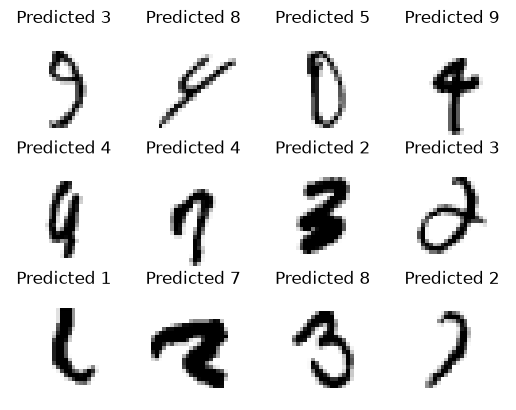

In [12]:
select = np.random.randint(xerrors.shape[0], size=12)
for index, value in enumerate(select):
    plt.subplot(3,4, index + 1)
    plt.axis("off")
    plt.imshow(xerrors[value], cmap=plt.cm.gray_r)
    plt.title(f"Predicted {yerrors[value]}")
plt.show()

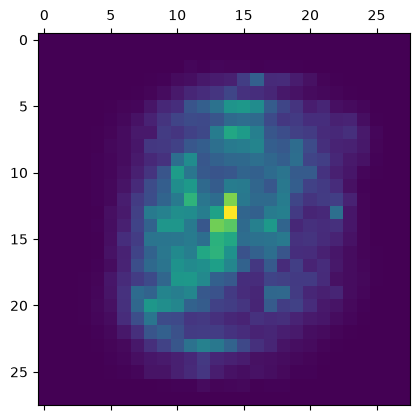

In [14]:
plt.matshow(model.feature_importances_.reshape(28,28))

In [15]:
v12 = np.arange(12)
v12

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [16]:
mat43 = v12.reshape(4,3)
mat43

array([[ 0,  1,  2],
       [ 3,  4,  5],
       [ 6,  7,  8],
       [ 9, 10, 11]])

In [18]:
mat34 = v12.reshape(-1, 4)
mat34

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [19]:
cube232 = v12.reshape(2,3,2)
cube232

array([[[ 0,  1],
        [ 2,  3],
        [ 4,  5]],

       [[ 6,  7],
        [ 8,  9],
        [10, 11]]])

In [20]:
cube232.reshape(6,2)

array([[ 0,  1],
       [ 2,  3],
       [ 4,  5],
       [ 6,  7],
       [ 8,  9],
       [10, 11]])